# Redes Neurais Convolucionais (CNNs) — Tutorial Completo

> **Fontes:** AIMA Cap. 22 · Warfield (TDS) · Jorgecardete (The Deep Hub) · CNN Explained · Notebook AC_2 IBMEC

---
## Sumário

**Parte 1 — Arquitetura e Camadas**
1. [Por que CNNs?](#parte1) — Problema das redes densas em imagens  
2. [Camada Convolucional](#conv) — Kernel, Feature Map, stride, padding  
3. [Função de Ativação](#relu) — ReLU e variantes  
4. [Camada de Pooling](#pool) — Max Pooling e Average Pooling  
5. [Batch Normalization](#bn) — Estabilização do treino  
6. [Flatten + Dense + Dropout](#flat) — Cabeça classificadora  
7. [Pipeline Completo Visualizado](#pipe) — Fluxo de dimensões tensor a tensor  

**Parte 2 — Cat / No Cat**

8. [Rede Densa (MLP)](#mlp) — Baseline sem convolução  
9. [CNN para Cat/No Cat](#cnn_cat) — Comparação direta  

**Parte 3 — MNIST**

10. [CNN para MNIST](#mnist) — Dataset, arquitetura, treino, avaliação

In [1]:
# ── Imports globais ──────────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch import optim
from torch.utils.data import DataLoader, TensorDataset, random_split

from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'PyTorch  : {torch.__version__}')
print(f'Dispositivo: {device}')

PyTorch  : 2.3.1+cpu
Dispositivo: cpu


---
<a id='parte1'></a>
## Parte 1 — Arquitetura e Camadas de uma CNN

### 1. Por que CNNs? O Problema das Redes Densas

Uma rede **densa** (MLP) conecta **cada** neurônio de uma camada a **todos** os neurônios da camada seguinte. Para imagens, isso gera um número absurdo de parâmetros:

| Imagem | Neurônios entrada | 1ª camada (64 neurônios) | Parâmetros só nessa camada |
|--------|------------------|--------------------------|-----------------------------|
| 28×28 (MNIST) | 784 | 64 | **50 176** |
| 64×64 (RGB) | 12 288 | 64 | **786 432** |
| 256×256 (RGB) | 196 608 | 64 | **12 582 912** |

Além do custo computacional, redes densas são **sensíveis a translações** — o mesmo objeto deslocado alguns pixels parece completamente diferente.

As CNNs resolvem ambos os problemas com **compartilhamento de pesos** (o mesmo kernel varre toda a imagem) e **invariância espacial**.

In [2]:
# ── Demonstração: custo de parâmetros MLP vs CNN ──────────────
configs = [
    ('28×28 gray', 28*28,  1),
    ('64×64 RGB',  64*64,  3),
    ('256×256 RGB',256*256,3),
]

print(f'{"Imagem":<18} {"Pixels":>10} {"MLP (64 neur.)":>16} {"CNN (32 ker. 3×3)":>20}')
print('─'*68)
for nome, px, ch in configs:
    mlp_params  = px * ch * 64
    cnn_params  = 3 * 3 * ch * 32   # 32 filtros 3×3
    reducao     = mlp_params / cnn_params
    print(f'{nome:<18} {px*ch:>10,} {mlp_params:>16,} {cnn_params:>10,}  ({reducao:.0f}× menos)')

Imagem                 Pixels   MLP (64 neur.)    CNN (32 ker. 3×3)
────────────────────────────────────────────────────────────────────
28×28 gray                784           50,176        288  (174× menos)
64×64 RGB              12,288          786,432        864  (910× menos)
256×256 RGB           196,608       12,582,912        864  (14564× menos)


---
<a id='conv'></a>
### 2. Camada Convolucional (`nn.Conv2d`)

A camada convolucional aplica **filtros (kernels)** sobre a imagem de entrada para extrair **feature maps**.

**Como funciona passo a passo:**
1. Posiciona o kernel de tamanho *k×k* no canto superior esquerdo da imagem  
2. Multiplica elemento a elemento e soma → um único valor  
3. Desloca o kernel pela quantidade definida pelo **stride**  
4. Repete até cobrir toda a imagem → forma o **feature map**  

$$\text{output}(i,j) = \sum_{m=0}^{k-1}\sum_{n=0}^{k-1} \text{input}(i\cdot s + m,\; j\cdot s + n) \times \text{kernel}(m, n)$$

**Hiperparâmetros principais:**

| Parâmetro | Efeito |
|-----------|--------|
| `out_channels` | Número de filtros → número de feature maps |
| `kernel_size` | Tamanho do campo receptivo local |
| `stride` | Passo do deslizamento (↑stride → ↓tamanho saída) |
| `padding` | Borda extra para preservar dimensões |

$$\text{H}_{out} = \left\lfloor \frac{H_{in} + 2p - k}{s} \right\rfloor + 1$$

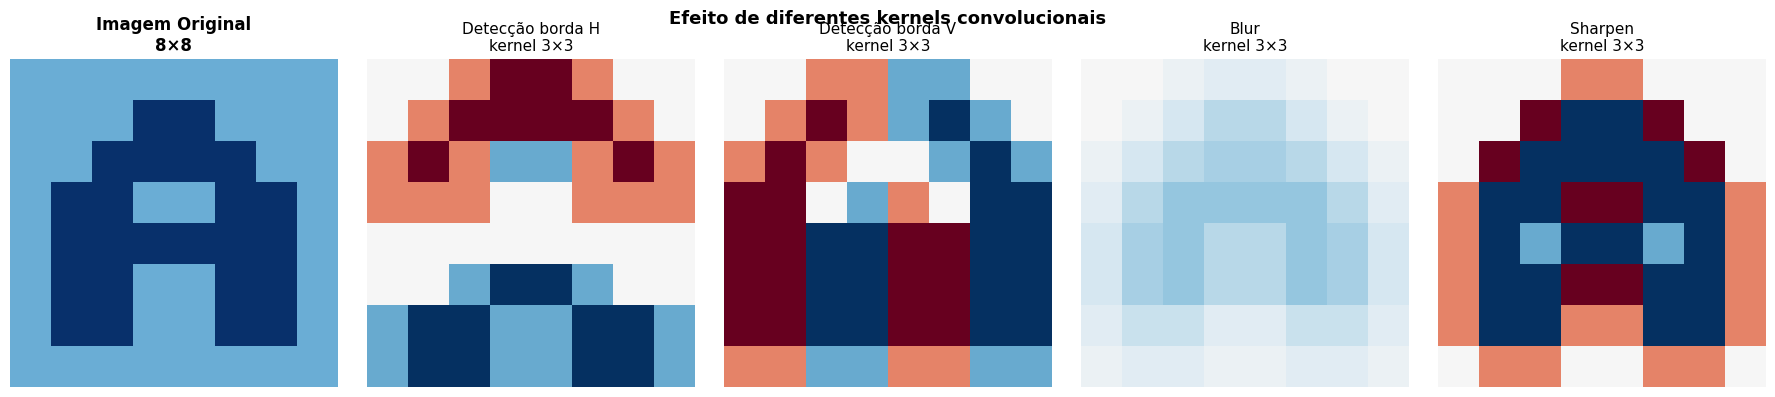

In [3]:
# ── Convolução manual visualizada ─────────────────────────────
from scipy import signal

# Imagem sintética 8×8
img = np.array([
    [0,0,0,0,0,0,0,0],
    [0,0,0,1,1,0,0,0],
    [0,0,1,1,1,1,0,0],
    [0,1,1,0,0,1,1,0],
    [0,1,1,1,1,1,1,0],
    [0,1,1,0,0,1,1,0],
    [0,1,1,0,0,1,1,0],
    [0,0,0,0,0,0,0,0],
], dtype=float)

kernels_demo = {
    'Detecção borda H': np.array([[-1,-1,-1],[0,0,0],[1,1,1]], float),
    'Detecção borda V': np.array([[-1,0,1],[-1,0,1],[-1,0,1]], float),
    'Blur':             np.ones((3,3), float) / 9,
    'Sharpen':          np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], float),
}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
axes[0].imshow(img, cmap='Blues', vmin=-1, vmax=1)
axes[0].set_title('Imagem Original\n8×8', fontsize=12, fontweight='bold')
axes[0].axis('off')

for ax, (nome, k) in zip(axes[1:], kernels_demo.items()):
    resultado = signal.convolve2d(img, k, mode='same')
    ax.imshow(resultado, cmap='RdBu', vmin=-2, vmax=2)
    ax.set_title(f'{nome}\nkernel 3×3', fontsize=11)
    ax.axis('off')

plt.suptitle('Efeito de diferentes kernels convolucionais', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [4]:
# ── Conv2d no PyTorch: dimensões passo a passo ────────────────
def dim_conv(H, k, p, s):
    return (H + 2*p - k) // s + 1

H = 28   # imagem MNIST
print('Entrada:', H, '×', H, '(1 canal)')
print()

camadas = [
    ('Conv2d', 1,  32, 3, 1, 1),   # (in_ch, out_ch, k, s, p)
    ('Conv2d', 32, 32, 3, 1, 1),
    ('Pool',   32, 32, 2, 2, 0),   # MaxPool
    ('Conv2d', 32, 64, 3, 1, 1),
    ('Pool',   64, 64, 2, 2, 0),
]

ch, h = 1, H
print(f'{"Camada":<22} {"in_ch":>5} {"out_ch":>7} {"k":>3} {"s":>3} {"p":>3}  {"Saída":>15}')
print('─'*65)
for tipo, ic, oc, k, s, p in camadas:
    h = dim_conv(h, k, p, s)
    ch = oc
    print(f'{tipo:<22} {ic:>5} {oc:>7} {k:>3} {s:>3} {p:>3}  {oc}×{h}×{h}  ({h*h*oc:,} valores)')

flatten = h * h * ch
print(f'\nFlatten → {flatten} neurônios')

Entrada: 28 × 28 (1 canal)

Camada                 in_ch  out_ch   k   s   p            Saída
─────────────────────────────────────────────────────────────────
Conv2d                     1      32   3   1   1  32×28×28  (25,088 valores)
Conv2d                    32      32   3   1   1  32×28×28  (25,088 valores)
Pool                      32      32   2   2   0  32×14×14  (6,272 valores)
Conv2d                    32      64   3   1   1  64×14×14  (12,544 valores)
Pool                      64      64   2   2   0  64×7×7  (3,136 valores)

Flatten → 3136 neurônios


---
<a id='relu'></a>
### 3. Função de Ativação

Após cada convolução aplica-se uma **não-linearidade**. Sem ela, empilhar camadas seria equivalente a uma única transformação linear.

| Função | Fórmula | Uso típico |
|--------|---------|------------|
| **ReLU** | $\max(0, x)$ | Camadas ocultas (padrão) |
| **Leaky ReLU** | $x$ se $x>0$, else $\alpha x$ | Evita neurônios mortos |
| **Sigmoid** | $\frac{1}{1+e^{-x}}$ | Saída binária |
| **Softmax** | $\frac{e^{x_i}}{\sum e^{x_j}}$ | Saída multiclasse |

> **Por que ReLU é o padrão?** Resolve o *vanishing gradient* de sigmoid/tanh, é computacionalmente barato e converge mais rápido.

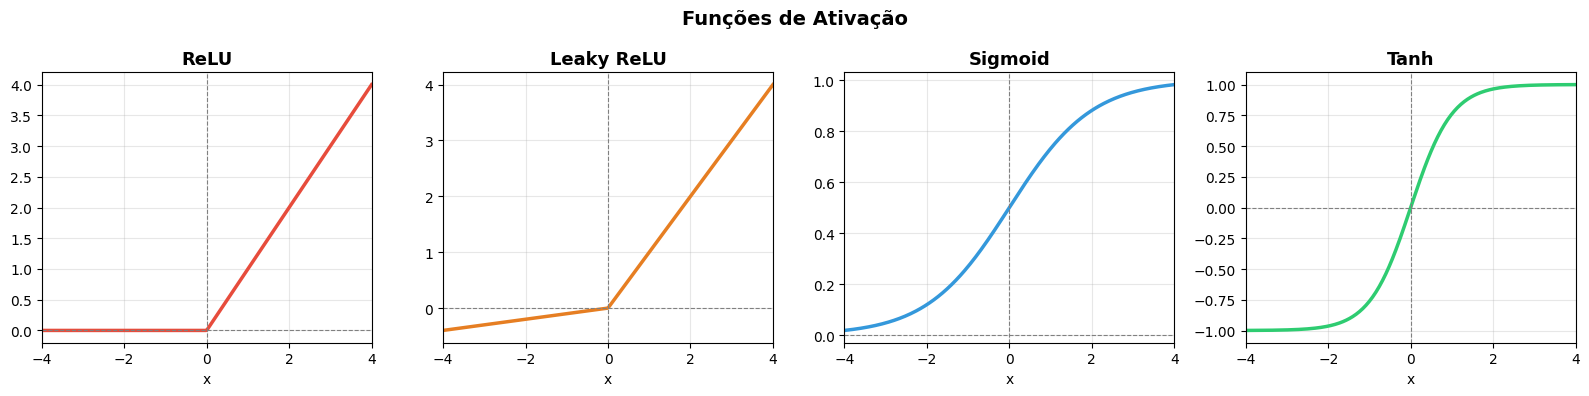

In [5]:
# ── Visualizando funções de ativação ─────────────────────────
x = torch.linspace(-4, 4, 300)

ativacoes = {
    'ReLU':        F.relu(x),
    'Leaky ReLU':  F.leaky_relu(x, 0.1),
    'Sigmoid':     torch.sigmoid(x),
    'Tanh':        torch.tanh(x),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=False)
cores = ['#e74c3c','#e67e22','#3498db','#2ecc71']

for ax, (nome, y), cor in zip(axes, ativacoes.items(), cores):
    ax.plot(x.numpy(), y.numpy(), color=cor, linewidth=2.5)
    ax.axhline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.axvline(0, color='gray', linewidth=0.8, linestyle='--')
    ax.set_title(nome, fontsize=13, fontweight='bold')
    ax.set_xlabel('x')
    ax.grid(True, alpha=0.3)
    ax.set_xlim(-4, 4)

plt.suptitle('Funções de Ativação', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='pool'></a>
### 4. Camada de Pooling (`nn.MaxPool2d`)

O pooling **reduz as dimensões espaciais** preservando as features mais relevantes. **Não tem parâmetros treináveis.**

- **Max Pooling:** seleciona o valor máximo da janela → detecta *se* a feature existe  
- **Average Pooling:** calcula a média → suaviza a representação  

> ⚠️ **Pooling NÃO reduz o número de canais** — apenas as dimensões espaciais (H e W).

Janela 2×2, stride=2: divide H e W **pela metade**.

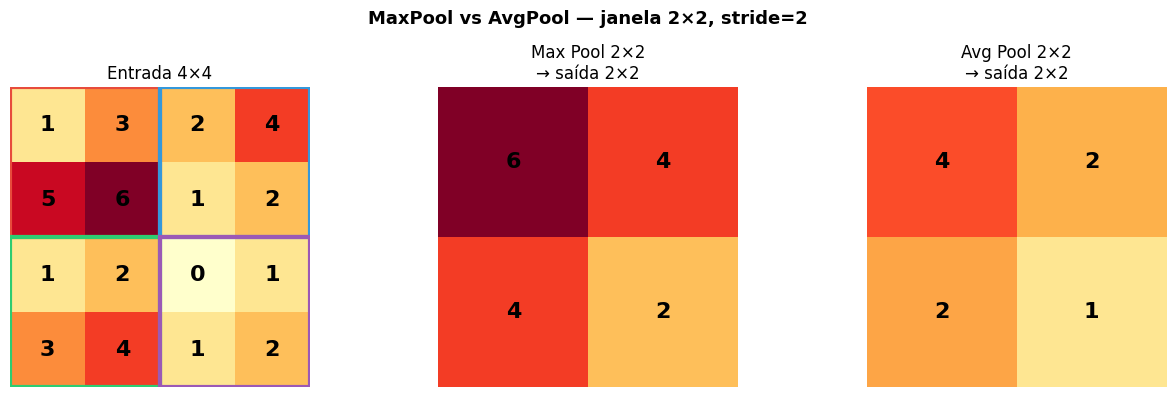

Entrada: (4, 4)  →  Saída: (2, 2)  (reduziu pela metade em H e W)


In [6]:
# ── Demonstração visual de MaxPool vs AvgPool ─────────────────
entrada = np.array([
    [1, 3, 2, 4],
    [5, 6, 1, 2],
    [1, 2, 0, 1],
    [3, 4, 1, 2]
], dtype=float)

def pool2x2_max(m):
    h, w = m.shape[0]//2, m.shape[1]//2
    out = np.zeros((h, w))
    for i in range(h):
        for j in range(w):
            out[i,j] = m[2*i:2*i+2, 2*j:2*j+2].max()
    return out

def pool2x2_avg(m):
    h, w = m.shape[0]//2, m.shape[1]//2
    out = np.zeros((h, w))
    for i in range(h):
        for j in range(w):
            out[i,j] = m[2*i:2*i+2, 2*j:2*j+2].mean()
    return out

max_out = pool2x2_max(entrada)
avg_out = pool2x2_avg(entrada)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, titulo, dados in zip(axes,
    ['Entrada 4×4', 'Max Pool 2×2\n→ saída 2×2', 'Avg Pool 2×2\n→ saída 2×2'],
    [entrada, max_out, avg_out]):
    im = ax.imshow(dados, cmap='YlOrRd', vmin=0, vmax=6)
    for i in range(dados.shape[0]):
        for j in range(dados.shape[1]):
            ax.text(j, i, f'{dados[i,j]:.0f}', ha='center', va='center',
                    fontsize=16, fontweight='bold', color='black')
    ax.set_title(titulo, fontsize=12)
    ax.axis('off')

# Destaque nas janelas 2×2
colors = ['#e74c3c','#3498db','#2ecc71','#9b59b6']
for idx, (ri, ci) in enumerate([(0,0),(0,2),(2,0),(2,2)]):
    rect = plt.Rectangle((ci-0.5, ri-0.5), 2, 2,
                          edgecolor=colors[idx], facecolor='none', linewidth=3)
    axes[0].add_patch(rect)

plt.suptitle('MaxPool vs AvgPool — janela 2×2, stride=2', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print(f'Entrada: {entrada.shape}  →  Saída: {max_out.shape}  (reduziu pela metade em H e W)')

---
<a id='bn'></a>
### 5. Batch Normalization (`nn.BatchNorm2d`)

À medida que os dados fluem pelas camadas, a escala dos valores se desvirtua — fenômeno chamado de **internal covariate shift**. O Batch Norm normaliza a saída de cada camada:

$$\hat{x} = \frac{x - \mu_B}{\sigma_B + \epsilon} \cdot \gamma + \beta$$

onde $\mu_B$ e $\sigma_B$ são a média e desvio do mini-batch, e $\gamma, \beta$ são **parâmetros aprendíveis**.

**Benefícios:**
- Treino mais estável e rápido  
- Permite usar taxas de aprendizado maiores  
- Atua como regularizador (reduz necessidade de Dropout)  
- Posicionamento típico: `Conv2d → BN → ReLU → Pool`

Task was destroyed but it is pending!
task: <Task pending name='Task-267' coro=<_async_in_context.<locals>.run_in_context_pre311() done, defined at C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\ipykernel\utils.py:76> wait_for=<Task pending name='Task-268' coro=<_async_in_context.<locals>.preserve_context() running at C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\ipykernel\utils.py:68> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\zmq\eventloop\zmqstream.py:564]>
C:\Users\domin\anaconda3\envs\cnn_env\lib\tokenize.py:527: RuntimeWarning: coroutine '_async_in_context.<locals>.preserve_context' was never awaited
  pseudomatch = _compile(PseudoToken).match(line, pos)
Task was destroyed but it is pending!
task: <Task pending name='Task-268' coro=<_async_in_context.<locals>.preserve_context() running at C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\ipykernel\utils.py:68> cb=[T

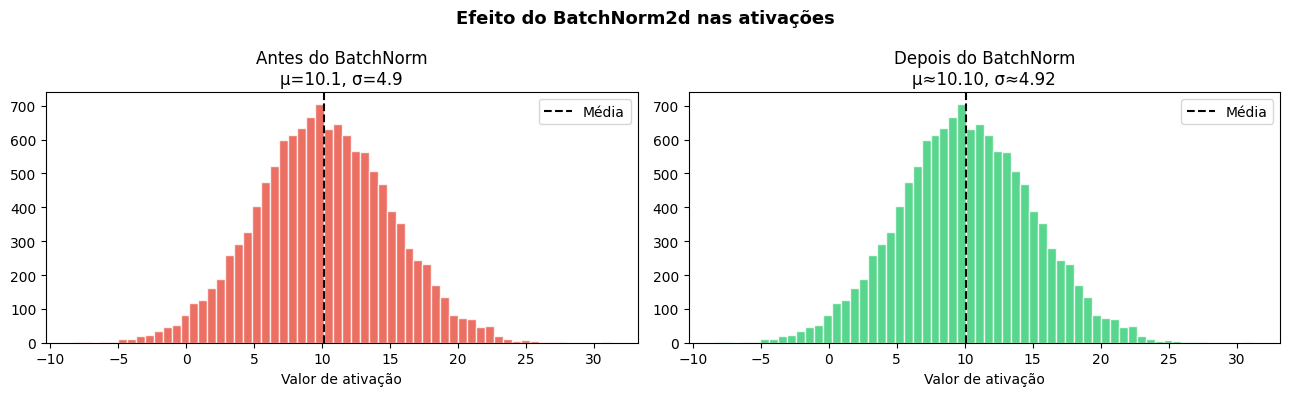

In [47]:
# ── Efeito do BatchNorm nas distribuições de ativação ─────────
torch.manual_seed(7)

# Simula saídas de uma convolução com distribuição deslocada
ativacoes_brutas = torch.randn(64, 32, 14, 14) * 5 + 10  # média=10, std=5

bn = nn.BatchNorm2d(32)
bn.eval()
with torch.no_grad():
    ativacoes_norm = bn(ativacoes_brutas)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sample = ativacoes_brutas[:, 0, :, :].flatten().numpy()
axes[0].hist(sample, bins=60, color='#e74c3c', alpha=0.8, edgecolor='white')
axes[0].set_title(f'Antes do BatchNorm\nμ={sample.mean():.1f}, σ={sample.std():.1f}', fontsize=12)
axes[0].set_xlabel('Valor de ativação')
axes[0].axvline(sample.mean(), color='black', linestyle='--', label='Média')
axes[0].legend()

sample_n = ativacoes_norm[:, 0, :, :].flatten().detach().numpy()
axes[1].hist(sample_n, bins=60, color='#2ecc71', alpha=0.8, edgecolor='white')
axes[1].set_title(f'Depois do BatchNorm\nμ≈{sample_n.mean():.2f}, σ≈{sample_n.std():.2f}', fontsize=12)
axes[1].set_xlabel('Valor de ativação')
axes[1].axvline(sample_n.mean(), color='black', linestyle='--', label='Média')
axes[1].legend()

plt.suptitle('Efeito do BatchNorm2d nas ativações', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
<a id='flat'></a>
### 6. Flatten → Dense → Dropout

**Flatten (`nn.Flatten`):**  
Converte o tensor 3D `[C × H × W]` em vetor 1D `[C×H×W]`. **Não altera os dados, apenas a forma.**

**Dense (`nn.Linear`):**  
Camadas totalmente conectadas que combinam as features extraídas para fazer a classificação final. Precisam das features como vetor 1D.

**Dropout (`nn.Dropout`):**  
Durante o treino, desativa aleatoriamente uma fração `p` dos neurônios em cada forward pass.  
- Força a rede a aprender representações redundantes  
- Regularizador eficiente contra *overfitting*  
- **Desativado automaticamente no modo `.eval()`**

In [8]:
# ── Demonstração: Flatten + Linear + Dropout ──────────────────
tensor_3d = torch.randn(1, 64, 6, 6)   # saída típica após poolings
print(f'Tensor 3D (C×H×W):   {list(tensor_3d.shape)}')

flat = nn.Flatten()
tensor_1d = flat(tensor_3d)
print(f'Após Flatten:         {list(tensor_1d.shape)}  (= 64×6×6 = {64*6*6})')

linear1 = nn.Linear(64*6*6, 128)
out1 = F.relu(linear1(tensor_1d))
print(f'Após Linear(2304→128)+ReLU: {list(out1.shape)}')

drop = nn.Dropout(p=0.2)
out_drop = drop(out1)
zeros = (out_drop == 0).sum().item()
print(f'Após Dropout(p=0.2): {list(out_drop.shape)}  ({zeros}/{128} neurônios zerados)')

linear2 = nn.Linear(128, 10)
logits = linear2(out_drop)
print(f'Após Linear(128→10): {list(logits.shape)}  ← logits para 10 classes')

probs = F.softmax(logits, dim=1)
print(f'Após Softmax:         {list(probs.shape)}  soma={probs.sum().item():.4f}')

Tensor 3D (C×H×W):   [1, 64, 6, 6]
Após Flatten:         [1, 2304]  (= 64×6×6 = 2304)
Após Linear(2304→128)+ReLU: [1, 128]
Após Dropout(p=0.2): [1, 128]  (79/128 neurônios zerados)
Após Linear(128→10): [1, 10]  ← logits para 10 classes
Após Softmax:         [1, 10]  soma=1.0000


---
<a id='pipe'></a>
### 7. Pipeline Completo — Fluxo de Dimensões

Ordem típica de uma CNN:  
`[Conv → BN → ReLU → Pool] × N` → `Flatten` → `[Linear → ReLU → Dropout] × M` → `Linear → Softmax`

In [9]:
# ── Pipeline visual: tensor atravessando cada camada ──────────
class CNNInspecionavel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1   = nn.Conv2d(1, 32, 3, padding=1)
        self.bn1     = nn.BatchNorm2d(32)
        self.conv2   = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2     = nn.BatchNorm2d(64)
        self.pool    = nn.MaxPool2d(2, 2)
        self.flatten = nn.Flatten()
        self.fc1     = nn.Linear(64*7*7, 128)
        self.dropout = nn.Dropout(0.25)
        self.fc2     = nn.Linear(128, 10)
        self.relu    = nn.ReLU()

    def forward(self, x, verbose=False):
        def log(nome, t):
            if verbose: print(f'  {nome:<35} → {list(t.shape)}')
        log('Entrada', x)
        x = self.relu(self.bn1(self.conv1(x)));  log('Conv1→BN→ReLU', x)
        x = self.pool(x);                        log('MaxPool', x)
        x = self.relu(self.bn2(self.conv2(x)));  log('Conv2→BN→ReLU', x)
        x = self.pool(x);                        log('MaxPool', x)
        x = self.flatten(x);                     log('Flatten', x)
        x = self.dropout(self.relu(self.fc1(x)));log('Linear1→ReLU→Dropout', x)
        x = self.fc2(x);                         log('Linear2 (logits)', x)
        return x

net_demo = CNNInspecionavel()
dummy = torch.randn(1, 1, 28, 28)   # 1 imagem MNIST

print('=== Fluxo do tensor pela CNN (imagem MNIST 28×28) ===')
with torch.no_grad():
    _ = net_demo(dummy, verbose=True)

total = sum(p.numel() for p in net_demo.parameters())
print(f'\nTotal de parâmetros: {total:,}')

=== Fluxo do tensor pela CNN (imagem MNIST 28×28) ===
  Entrada                             → [1, 1, 28, 28]
  Conv1→BN→ReLU                       → [1, 32, 28, 28]
  MaxPool                             → [1, 32, 14, 14]
  Conv2→BN→ReLU                       → [1, 64, 14, 14]
  MaxPool                             → [1, 64, 7, 7]
  Flatten                             → [1, 3136]
  Linear1→ReLU→Dropout                → [1, 128]
  Linear2 (logits)                    → [1, 10]

Total de parâmetros: 421,834


---
## Parte 2 — Cat / No Cat: MLP vs CNN

<a id='mlp'></a>
### 8. Rede Densa (MLP) — Baseline

Usaremos o dataset **CIFAR-10** filtrando apenas a classe *gato* (label=3) vs *todas as outras* — problema binário idêntico ao clássico "Cat/No Cat".

In [10]:
# ── Carregando CIFAR-10 e criando Cat / No Cat ─────────────────
transform_cifar = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,0.5,0.5),(0.5,0.5,0.5))
])

cifar_train = datasets.CIFAR10('.', train=True,  download=True, transform=transform_cifar)
cifar_test  = datasets.CIFAR10('.', train=False, download=True, transform=transform_cifar)

def cifar_to_cat_nocat(dataset):
    X = torch.stack([dataset[i][0] for i in range(len(dataset))])
    y = torch.tensor([1 if dataset[i][1]==3 else 0 for i in range(len(dataset))])
    return X, y.float()

print('Preparando dados... (pode levar ~1 min)')
X_train, y_train = cifar_to_cat_nocat(cifar_train)
X_test,  y_test  = cifar_to_cat_nocat(cifar_test)

print(f'Treino: {X_train.shape}  — Gatos: {y_train.sum():.0f} / Não-gatos: {(1-y_train).sum():.0f}')
print(f'Teste:  {X_test.shape}')

100%|██████████| 170498071/170498071 [39:26<00:00, 72055.58it/s] 


Extracting .\cifar-10-python.tar.gz to .
Files already downloaded and verified
Preparando dados... (pode levar ~1 min)
Treino: torch.Size([50000, 3, 32, 32])  — Gatos: 5000 / Não-gatos: 45000
Teste:  torch.Size([10000, 3, 32, 32])


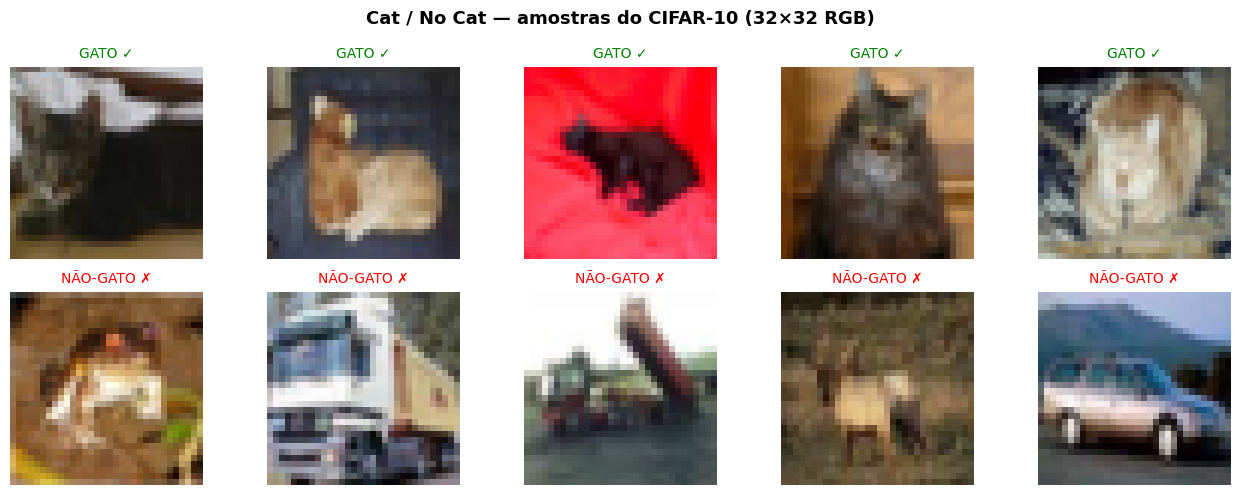

In [11]:
# ── Visualizando amostras ──────────────────────────────────────
classes_cifar = ['avião','automóvel','pássaro','gato','cervo',
                 'cachorro','sapo','cavalo','navio','caminhão']

idx_gatos   = (y_train == 1).nonzero(as_tuple=True)[0][:5]
idx_nogatos = (y_train == 0).nonzero(as_tuple=True)[0][:5]

fig, axes = plt.subplots(2, 5, figsize=(13, 5))
for col, idx in enumerate(idx_gatos):
    img = X_train[idx].permute(1,2,0).numpy() * 0.5 + 0.5
    axes[0, col].imshow(np.clip(img, 0, 1))
    axes[0, col].set_title('GATO ✓', color='green', fontsize=10)
    axes[0, col].axis('off')

for col, idx in enumerate(idx_nogatos):
    img = X_train[idx].permute(1,2,0).numpy() * 0.5 + 0.5
    axes[1, col].imshow(np.clip(img, 0, 1))
    axes[1, col].set_title('NÃO-GATO ✗', color='red', fontsize=10)
    axes[1, col].axis('off')

plt.suptitle('Cat / No Cat — amostras do CIFAR-10 (32×32 RGB)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [29]:
# ── DataLoaders ───────────────────────────────────────────────
BATCH = 256
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_test,  y_test),  batch_size=BATCH)

In [30]:
# ── Modelo 1: MLP (rede densa) ────────────────────────────────
class MLP_CatNoCat(nn.Module):
    """
    Rede totalmente conectada (sem convolução).
    Entrada: imagem 32×32×3 → achatada em 3072 valores.
    """
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3*32*32, 512),  nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(512, 256),      nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128),      nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 1),
            nn.Sigmoid()
        )
    def forward(self, x):
        return self.net(x).squeeze(1)

mlp = MLP_CatNoCat().to(device)
params_mlp = sum(p.numel() for p in mlp.parameters())
print(mlp)
print(f'\nParâmetros MLP: {params_mlp:,}')

MLP_CatNoCat(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=512, out_features=256, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.3, inplace=False)
    (7): Linear(in_features=256, out_features=128, bias=True)
    (8): ReLU()
    (9): Dropout(p=0.3, inplace=False)
    (10): Linear(in_features=128, out_features=1, bias=True)
    (11): Sigmoid()
  )
)

Parâmetros MLP: 1,737,729


In [31]:
# ── Função de treino reutilizável ─────────────────────────────
def treinar(modelo, train_loader, test_loader, epochs=15, lr=1e-3, nome='Modelo'):
    otimizador = optim.Adam(modelo.parameters(), lr=lr)
    criterio   = nn.BCELoss()
    hist = {'train_loss':[], 'test_loss':[], 'train_acc':[], 'test_acc':[]}

    for ep in range(1, epochs+1):
        modelo.train()
        tl, tc, tn = 0, 0, 0
        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)
            otimizador.zero_grad()
            pred = modelo(Xb)
            loss = criterio(pred, yb)
            loss.backward()
            otimizador.step()
            tl += loss.item() * len(yb)
            tc += ((pred > 0.5).float() == yb).sum().item()
            tn += len(yb)

        modelo.eval()
        vl, vc, vn = 0, 0, 0
        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                pred = modelo(Xb)
                loss = criterio(pred, yb)
                vl += loss.item() * len(yb)
                vc += ((pred > 0.5).float() == yb).sum().item()
                vn += len(yb)

        hist['train_loss'].append(tl/tn); hist['test_loss'].append(vl/vn)
        hist['train_acc'].append(tc/tn);  hist['test_acc'].append(vc/vn)

        if ep % 5 == 0 or ep == 1:
            print(f'[{nome}] Época {ep:2d}/{epochs} | '
                  f'Loss treino={tl/tn:.4f} | Acc treino={tc/tn:.3f} | '
                  f'Acc teste={vc/vn:.3f}')
    return hist

print('Treinando MLP...')
hist_mlp = treinar(mlp, train_loader, test_loader, epochs=15, nome='MLP')

Treinando MLP...
[MLP] Época  1/15 | Loss treino=0.3098 | Acc treino=0.900 | Acc teste=0.900
[MLP] Época  5/15 | Loss treino=0.2609 | Acc treino=0.900 | Acc teste=0.900
[MLP] Época 10/15 | Loss treino=0.2354 | Acc treino=0.904 | Acc teste=0.902
[MLP] Época 15/15 | Loss treino=0.2065 | Acc treino=0.913 | Acc teste=0.897


---
<a id='cnn_cat'></a>
### 9. CNN para Cat / No Cat

In [32]:
# ── Modelo 2: CNN ─────────────────────────────────────────────
class CNN_CatNoCat(nn.Module):
    """
    CNN para classificação binária Cat / No Cat.
    Entrada: imagem RGB 32×32.

    Bloco convolucional:
        Conv2d → BatchNorm2d → ReLU → MaxPool2d

    Cabeça classificadora:
        Flatten → Linear → ReLU → Dropout → Linear → Sigmoid
    """
    def __init__(self):
        super().__init__()
        # ── Extrator de features ──────────────────────────────
        self.bloco1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),   # 32×32 → 32×32
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)                             # 32×32 → 16×16
        )
        self.bloco2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),  # 16×16 → 16×16
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)                             # 16×16 → 8×8
        )
        self.bloco3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1), # 8×8 → 8×8
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)                             # 8×8 → 4×4
        )
        # ── Classificador ─────────────────────────────────────
        self.classificador = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*4*4, 256),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.bloco1(x)
        x = self.bloco2(x)
        x = self.bloco3(x)
        return self.classificador(x).squeeze(1)

cnn_cat = CNN_CatNoCat().to(device)
params_cnn = sum(p.numel() for p in cnn_cat.parameters())
print(cnn_cat)
print(f'\nParâmetros CNN: {params_cnn:,}')
print(f'Parâmetros MLP: {params_mlp:,}')

CNN_CatNoCat(
  (bloco1): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloco2): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (bloco3): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classificador): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, ou

In [33]:
print('Treinando CNN...')
hist_cnn = treinar(cnn_cat, train_loader, test_loader, epochs=15, nome='CNN')

Treinando CNN...
[CNN] Época  1/15 | Loss treino=0.2813 | Acc treino=0.898 | Acc teste=0.900
[CNN] Época  5/15 | Loss treino=0.1957 | Acc treino=0.918 | Acc teste=0.912
[CNN] Época 10/15 | Loss treino=0.1232 | Acc treino=0.951 | Acc teste=0.922
[CNN] Época 15/15 | Loss treino=0.0631 | Acc treino=0.980 | Acc teste=0.921


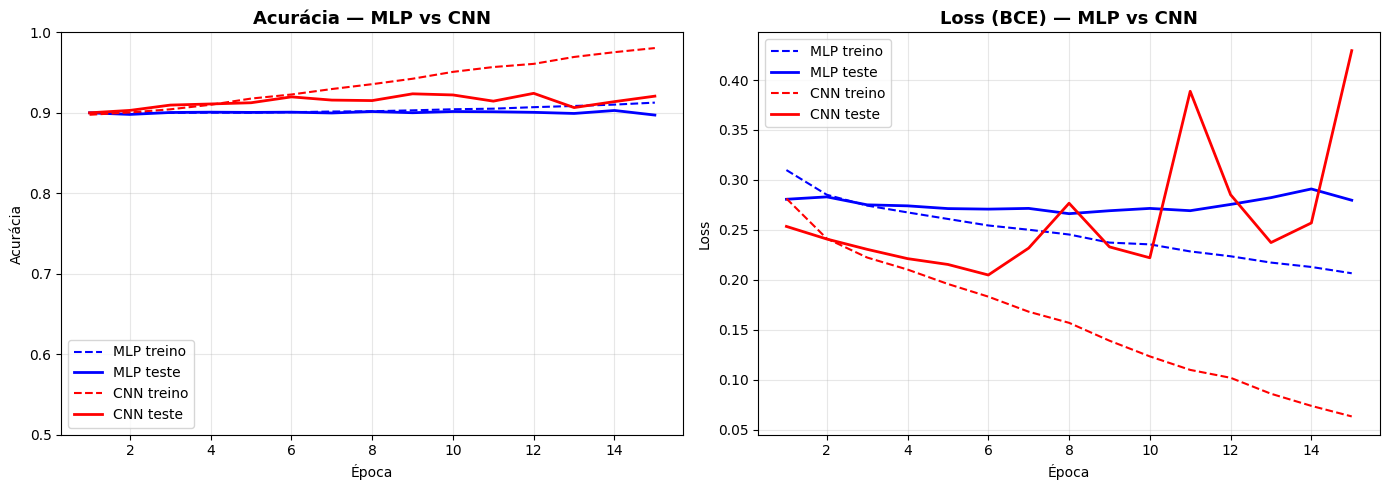

  Acurácia final no TESTE
  MLP: 89.72%   |   CNN: 92.07%
  Ganho CNN: +2.35 pontos percentuais
  Parâmetros MLP: 1,737,729  |  CNN: 618,497


In [40]:
# ── Comparação MLP vs CNN ─────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
eps = range(1, 16)

axes[0].plot(eps, hist_mlp['train_acc'], 'b--', label='MLP treino')
axes[0].plot(eps, hist_mlp['test_acc'],  'b-',  label='MLP teste',  linewidth=2)
axes[0].plot(eps, hist_cnn['train_acc'], 'r--', label='CNN treino')
axes[0].plot(eps, hist_cnn['test_acc'],  'r-',  label='CNN teste',  linewidth=2)
axes[0].set_title('Acurácia — MLP vs CNN', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Acurácia')
axes[0].legend(); axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(0.5, 1.0)

axes[1].plot(eps, hist_mlp['train_loss'], 'b--', label='MLP treino')
axes[1].plot(eps, hist_mlp['test_loss'],  'b-',  label='MLP teste',  linewidth=2)
axes[1].plot(eps, hist_cnn['train_loss'], 'r--', label='CNN treino')
axes[1].plot(eps, hist_cnn['test_loss'],  'r-',  label='CNN teste',  linewidth=2)
axes[1].set_title('Loss (BCE) — MLP vs CNN', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

acc_mlp = hist_mlp['test_acc'][-1]*100
acc_cnn = hist_cnn['test_acc'][-1]*100
#print(f'\n{'-'*45}')
print(f'  Acurácia final no TESTE')
print(f'  MLP: {acc_mlp:.2f}%   |   CNN: {acc_cnn:.2f}%')
print(f'  Ganho CNN: +{acc_cnn-acc_mlp:.2f} pontos percentuais')
print(f'  Parâmetros MLP: {params_mlp:,}  |  CNN: {params_cnn:,}')
#print(f'{'_'*45}')

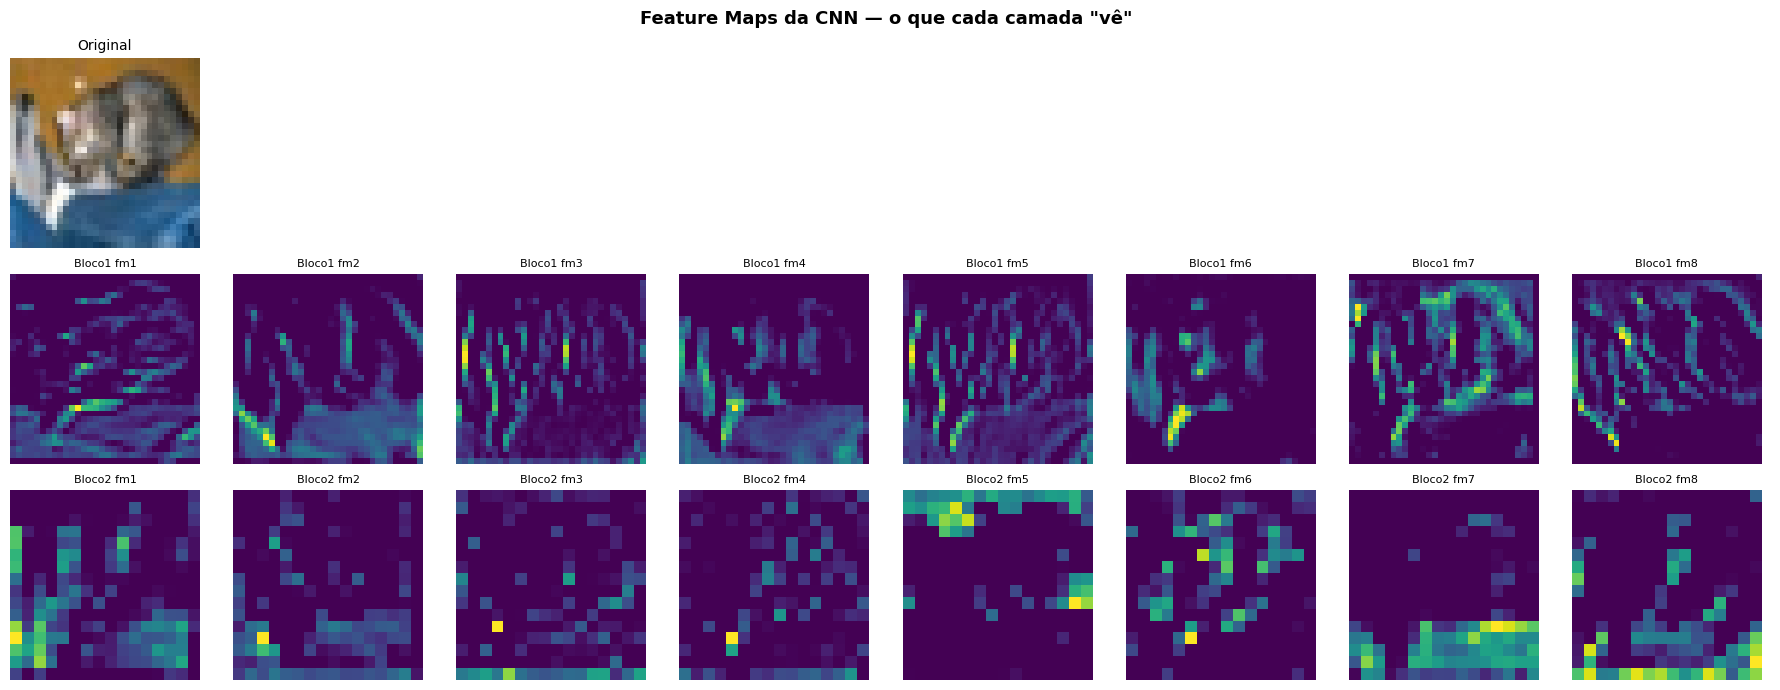

In [41]:
# ── Visualizando feature maps da CNN ─────────────────────────
cnn_cat.eval()
sample_img = X_test[0:1].to(device)

with torch.no_grad():
    fm1 = cnn_cat.bloco1[:-1](sample_img)   # depois do ReLU, antes do pool
    fm2 = cnn_cat.bloco2[:-1](cnn_cat.bloco1(sample_img))

fig, axes = plt.subplots(3, 8, figsize=(18, 7))

img_orig = sample_img[0].cpu().permute(1,2,0).numpy() * 0.5 + 0.5
axes[0, 0].imshow(np.clip(img_orig, 0, 1))
axes[0, 0].set_title('Original', fontsize=10)
axes[0, 0].axis('off')
for i in range(1, 8):
    axes[0, i].axis('off')

for i in range(8):
    axes[1, i].imshow(fm1[0, i].cpu().numpy(), cmap='viridis')
    axes[1, i].set_title(f'Bloco1 fm{i+1}', fontsize=8)
    axes[1, i].axis('off')

for i in range(8):
    axes[2, i].imshow(fm2[0, i].cpu().numpy(), cmap='viridis')
    axes[2, i].set_title(f'Bloco2 fm{i+1}', fontsize=8)
    axes[2, i].axis('off')

plt.suptitle('Feature Maps da CNN — o que cada camada "vê"', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Parte 3 — MNIST com CNN

<a id='mnist'></a>
### 10. CNN para MNIST

O **MNIST** contém 70.000 imagens de dígitos manuscritos (0–9), em escala de cinza, 28×28 pixels. É o "Hello World" do deep learning para imagens.

In [12]:
# ── Etapa 1: Carregando o MNIST ───────────────────────────────
torch.manual_seed(123)

transform_mnist = transforms.ToTensor()

# Espelho confiável
datasets.MNIST.mirrors = ['https://ossci-datasets.s3.amazonaws.com/mnist/']

mnist_train = datasets.MNIST('.', train=True,  download=True, transform=transform_mnist)
mnist_test  = datasets.MNIST('.', train=False, download=True, transform=transform_mnist)

train_mnist_loader = DataLoader(mnist_train, batch_size=64, shuffle=True)
test_mnist_loader  = DataLoader(mnist_test,  batch_size=64)

print(f'Treino: {mnist_train.data.shape}  — {len(mnist_train)} imagens')
print(f'Teste:  {mnist_test.data.shape}   — {len(mnist_test)} imagens')

100%|██████████| 9912422/9912422 [00:06<00:00, 1462734.88it/s]


Extracting .\MNIST\raw\train-images-idx3-ubyte.gz to .\MNIST\raw



100%|██████████| 28881/28881 [00:00<00:00, 252348.15it/s]


Extracting .\MNIST\raw\train-labels-idx1-ubyte.gz to .\MNIST\raw



100%|██████████| 1648877/1648877 [00:00<00:00, 1965677.80it/s]


Extracting .\MNIST\raw\t10k-images-idx3-ubyte.gz to .\MNIST\raw



100%|██████████| 4542/4542 [00:00<00:00, 4538001.14it/s]

Extracting .\MNIST\raw\t10k-labels-idx1-ubyte.gz to .\MNIST\raw

Treino: torch.Size([60000, 28, 28])  — 60000 imagens
Teste:  torch.Size([10000, 28, 28])   — 10000 imagens


In [14]:
label

5

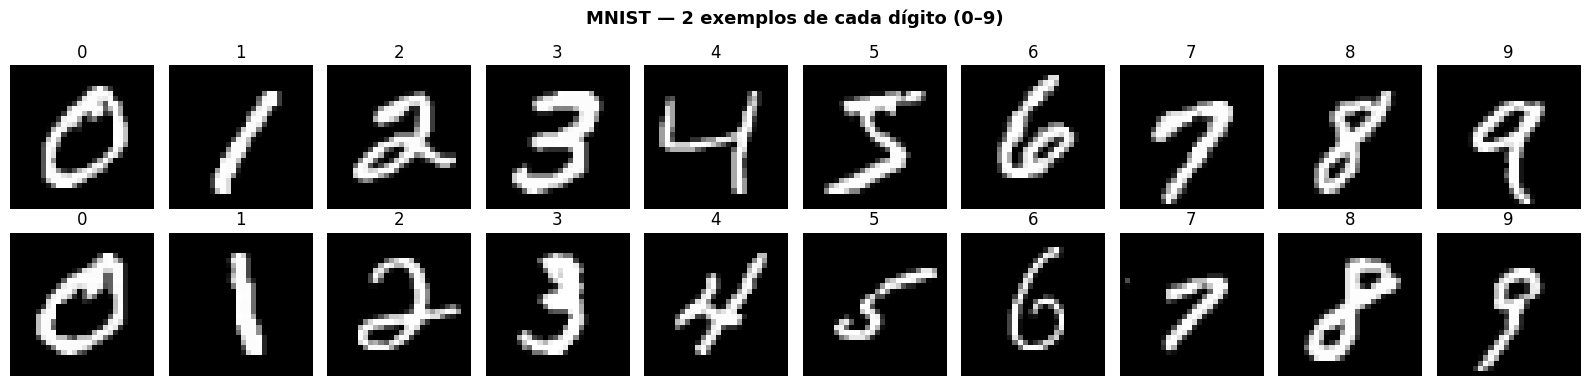

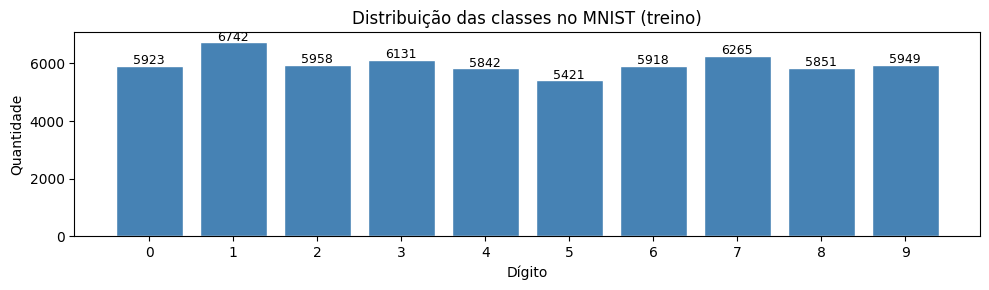

In [16]:
# ── Etapa 2: Explorando o dataset ────────────────────────────
fig, axes = plt.subplots(2, 10, figsize=(16, 4))
classes_por_digito = {d: [] for d in range(10)}

for img, label in mnist_train:
    if len(classes_por_digito[label]) < 2:
        classes_por_digito[label].append(img)
    if all(len(v) == 2 for v in classes_por_digito.values()):
        break

for d in range(10):
    for row in range(2):
        axes[row, d].imshow(classes_por_digito[d][row].squeeze(), cmap='gray')
        axes[row, d].set_title(str(d), fontsize=12)
        axes[row, d].axis('off')

plt.suptitle('MNIST — 2 exemplos de cada dígito (0–9)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Distribuição das classes
contagens = torch.bincount(mnist_train.targets)
fig, ax = plt.subplots(figsize=(10, 3))
ax.bar(range(10), contagens.numpy(), color='steelblue', edgecolor='white')
ax.set_xticks(range(10))
ax.set_title('Distribuição das classes no MNIST (treino)', fontsize=12)
ax.set_xlabel('Dígito'); ax.set_ylabel('Quantidade')
for i, v in enumerate(contagens):
    ax.text(i, v+50, str(v.item()), ha='center', fontsize=9)
plt.tight_layout()
plt.show()

In [17]:
# ── Etapa 3: Definindo a CNN ──────────────────────────────────
class CNN_MNIST(nn.Module):
    """
    CNN para classificação de dígitos MNIST (10 classes).

    Arquitetura:
      Bloco 1: Conv2d(1→32, 3×3) → BN → ReLU → MaxPool(2×2)
               Entrada 28×28 → Saída 13×13
      Bloco 2: Conv2d(32→32, 3×3) → BN → ReLU → MaxPool(2×2)
               Entrada 13×13 → Saída 6×6
      Flatten: 32×6×6 = 1152 → vetor 1D
      FC1:     1152 → 128 + ReLU + Dropout(0.2)
      FC2:     128  → 128 + ReLU + Dropout(0.2)
      Saída:   128  → 10  (CrossEntropyLoss aplica Softmax)
    """
    def __init__(self):
        super().__init__()
        self.conv1      = nn.Conv2d(1, 32, kernel_size=(3,3))
        self.conv2      = nn.Conv2d(32, 32, kernel_size=(3,3))
        self.activation = nn.ReLU()
        self.bnorm      = nn.BatchNorm2d(32)
        self.pool       = nn.MaxPool2d(kernel_size=(2,2), stride=(2,2))
        self.flatten    = nn.Flatten(start_dim=1)
        self.linear1    = nn.Linear(800, 128)
        self.linear2    = nn.Linear(128, 128)
        self.output     = nn.Linear(128, 10)
        self.dropout    = nn.Dropout(p=0.2)

    def forward(self, X):
        X = self.pool(self.bnorm(self.activation(self.conv1(X))))
        X = self.pool(self.bnorm(self.activation(self.conv2(X))))
        X = self.flatten(X)
        X = self.dropout(self.activation(self.linear1(X)))
        X = self.dropout(self.activation(self.linear2(X)))
        X = self.output(X)
        return X

net_mnist = CNN_MNIST()
print(net_mnist)

# Verifica as dimensões
x_demo = torch.randn(1, 1, 28, 28)
with torch.no_grad():
    out = net_mnist(x_demo)
print(f'\nSaída para entrada 1×1×28×28: {list(out.shape)} (10 logits)')
print(f'Total de parâmetros: {sum(p.numel() for p in net_mnist.parameters()):,}')

CNN_MNIST(
  (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
  (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1))
  (activation): ReLU()
  (bnorm): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=800, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=10, bias=True)
  (dropout): Dropout(p=0.2, inplace=False)
)

Saída para entrada 1×1×28×28: [1, 10] (10 logits)
Total de parâmetros: 129,962


In [26]:
# ── Etapa 4: Treinamento ──────────────────────────────────────
device_mnist = 'cpu'  # troque por 'cuda' se disponível
net_mnist = CNN_MNIST().to(device_mnist)

criterion_mnist = nn.CrossEntropyLoss()
optimizer_mnist = optim.Adam(net_mnist.parameters())

NUM_EPOCHS = 100
hist_mnist = {'train_loss':[], 'train_acc':[], 'test_loss':[], 'test_acc':[]}

for epoch in range(1, NUM_EPOCHS+1):
    # ── Treino ──
    net_mnist.train()
    tl, tc, tn = 0, 0, 0
    for Xb, yb in train_mnist_loader:
        Xb, yb = Xb.to(device_mnist), yb.to(device_mnist)
        optimizer_mnist.zero_grad()
        logits = net_mnist(Xb)
        loss = criterion_mnist(logits, yb)
        loss.backward()
        optimizer_mnist.step()
        tl += loss.item() * len(yb)
        tc += (logits.argmax(1) == yb).sum().item()
        tn += len(yb)

    # ── Validação ──
    net_mnist.eval()
    vl, vc, vn = 0, 0, 0
    with torch.no_grad():
        for Xb, yb in test_mnist_loader:
            Xb, yb = Xb.to(device_mnist), yb.to(device_mnist)
            logits = net_mnist(Xb)
            loss = criterion_mnist(logits, yb)
            vl += loss.item() * len(yb)
            vc += (logits.argmax(1) == yb).sum().item()
            vn += len(yb)

    hist_mnist['train_loss'].append(tl/tn); hist_mnist['test_loss'].append(vl/vn)
    hist_mnist['train_acc'].append(tc/tn);  hist_mnist['test_acc'].append(vc/vn)

    print(f'Época {epoch:2d}/{NUM_EPOCHS} | '
          f'Loss: treino={tl/tn:.4f} teste={vl/vn:.4f} | '
          f'Acc: treino={tc/tn:.4f} teste={vc/vn:.4f}')

Época  1/100 | Loss: treino=0.1327 teste=0.9550 | Acc: treino=0.9598 teste=0.7382
Época  2/100 | Loss: treino=0.0501 teste=1.9200 | Acc: treino=0.9849 teste=0.3107
Época  3/100 | Loss: treino=0.0372 teste=2.4270 | Acc: treino=0.9885 teste=0.2586
Época  4/100 | Loss: treino=0.0305 teste=2.4950 | Acc: treino=0.9909 teste=0.3609
Época  5/100 | Loss: treino=0.0251 teste=4.1262 | Acc: treino=0.9920 teste=0.1945
Época  6/100 | Loss: treino=0.0237 teste=3.5808 | Acc: treino=0.9930 teste=0.2332
Época  7/100 | Loss: treino=0.0202 teste=5.1822 | Acc: treino=0.9942 teste=0.1135
Época  8/100 | Loss: treino=0.0193 teste=5.2291 | Acc: treino=0.9941 teste=0.1135
Época  9/100 | Loss: treino=0.0177 teste=5.2735 | Acc: treino=0.9942 teste=0.1135
Época 10/100 | Loss: treino=0.0153 teste=6.1322 | Acc: treino=0.9953 teste=0.1151
Época 11/100 | Loss: treino=0.0136 teste=6.3686 | Acc: treino=0.9961 teste=0.1135
Época 12/100 | Loss: treino=0.0158 teste=5.4250 | Acc: treino=0.9952 teste=0.1154
Época 13/100 | L

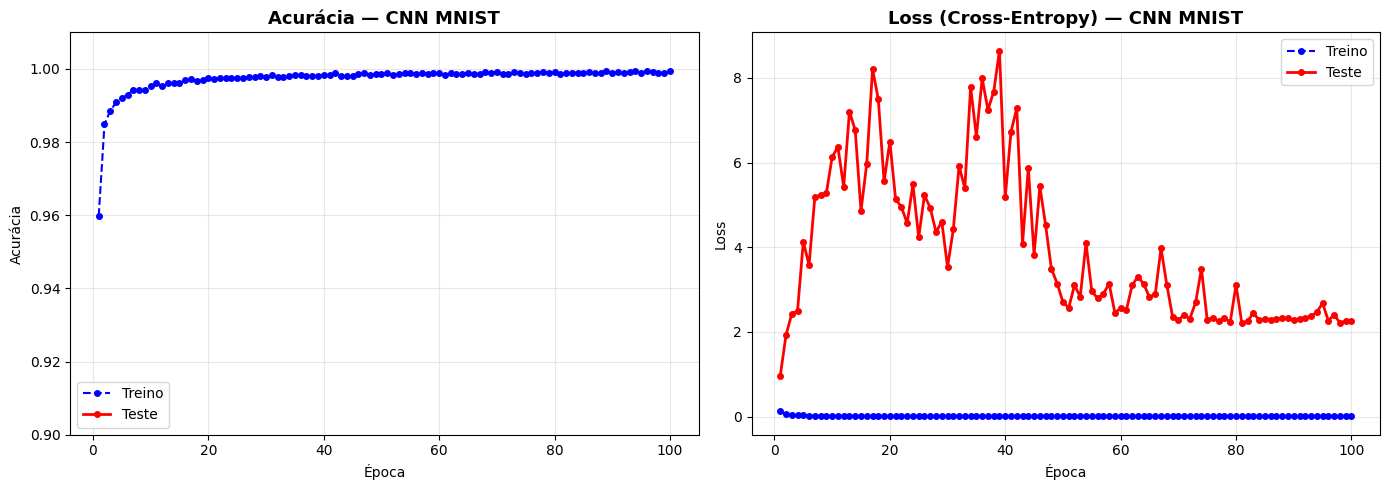


Acurácia final no TESTE: 11.59%


In [42]:
# ── Etapa 5: Curvas de aprendizado ───────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
eps = range(1, NUM_EPOCHS+1)

axes[0].plot(eps, hist_mnist['train_acc'], 'b--o', label='Treino', markersize=4)
axes[0].plot(eps, hist_mnist['test_acc'],  'r-o',  label='Teste',  markersize=4, linewidth=2)
axes[0].set_title('Acurácia — CNN MNIST', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Acurácia')
axes[0].legend(); axes[0].grid(True, alpha=0.3); axes[0].set_ylim(0.9, 1.01)

axes[1].plot(eps, hist_mnist['train_loss'], 'b--o', label='Treino', markersize=4)
axes[1].plot(eps, hist_mnist['test_loss'],  'r-o',  label='Teste',  markersize=4, linewidth=2)
axes[1].set_title('Loss (Cross-Entropy) — CNN MNIST', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\nAcurácia final no TESTE: {hist_mnist["test_acc"][-1]*100:.2f}%')

=== Relatório de Classificação ===
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       980
           1       0.13      1.00      0.23      1135
           2       0.00      0.00      0.00      1032
           3       0.00      0.00      0.00      1010
           4       0.00      0.00      0.00       982
           5       0.00      0.00      0.00       892
           6       0.00      0.00      0.00       958
           7       0.00      0.00      0.00      1028
           8       0.02      0.02      0.02       974
           9       0.00      0.00      0.00      1009

    accuracy                           0.12     10000
   macro avg       0.01      0.10      0.03     10000
weighted avg       0.02      0.12      0.03     10000



C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\domin\anaconda3\envs\cnn_env\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result

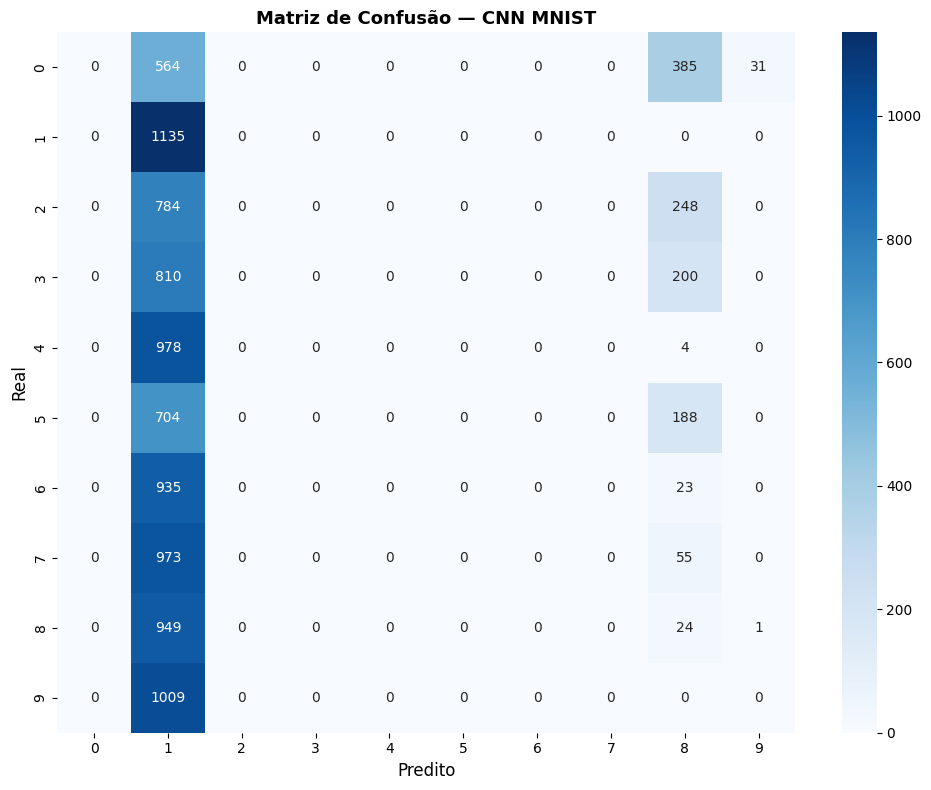

In [43]:
# ── Etapa 6: Avaliação completa e matriz de confusão ─────────
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

net_mnist.eval()
all_preds, all_labels = [], []

with torch.no_grad():
    for Xb, yb in test_mnist_loader:
        Xb = Xb.to(device_mnist)
        logits = net_mnist(Xb)
        preds = logits.argmax(dim=1).cpu()
        all_preds.extend(preds.numpy())
        all_labels.extend(yb.numpy())

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)

print('=== Relatório de Classificação ===')
print(classification_report(all_labels, all_preds,
                             target_names=[str(i) for i in range(10)]))

cm = confusion_matrix(all_labels, all_preds)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=range(10), yticklabels=range(10))
ax.set_xlabel('Predito', fontsize=12)
ax.set_ylabel('Real', fontsize=12)
ax.set_title('Matriz de Confusão — CNN MNIST', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

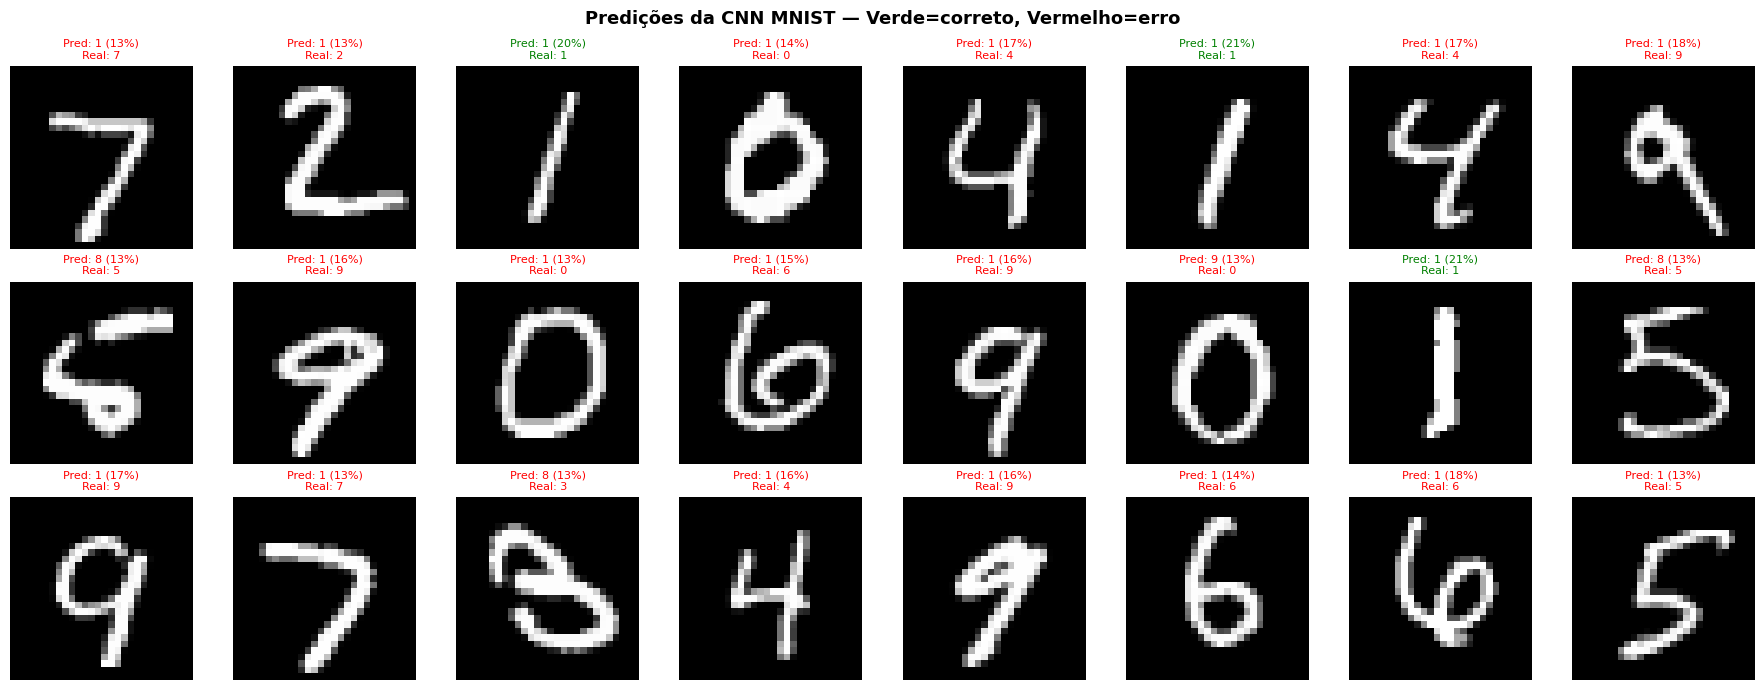

In [44]:
# ── Etapa 7: Predições individuais ───────────────────────────
net_mnist.eval()
amostra_imgs, amostra_labels = next(iter(test_mnist_loader))

with torch.no_grad():
    logits = net_mnist(amostra_imgs.to(device_mnist))
    probs  = F.softmax(logits, dim=1)
    preds  = logits.argmax(dim=1).cpu()

fig, axes = plt.subplots(3, 8, figsize=(18, 7))
for idx, ax in enumerate(axes.flatten()):
    img = amostra_imgs[idx].squeeze().numpy()
    pred = preds[idx].item()
    real = amostra_labels[idx].item()
    conf = probs[idx, pred].item() * 100
    cor  = 'green' if pred == real else 'red'
    ax.imshow(img, cmap='gray')
    ax.set_title(f'Pred: {pred} ({conf:.0f}%)\nReal: {real}',
                 color=cor, fontsize=8)
    ax.axis('off')

plt.suptitle('Predições da CNN MNIST — Verde=correto, Vermelho=erro',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Pesos conv1: [32, 1, 3, 3]  (32 filtros, 1 canal, 3×3)


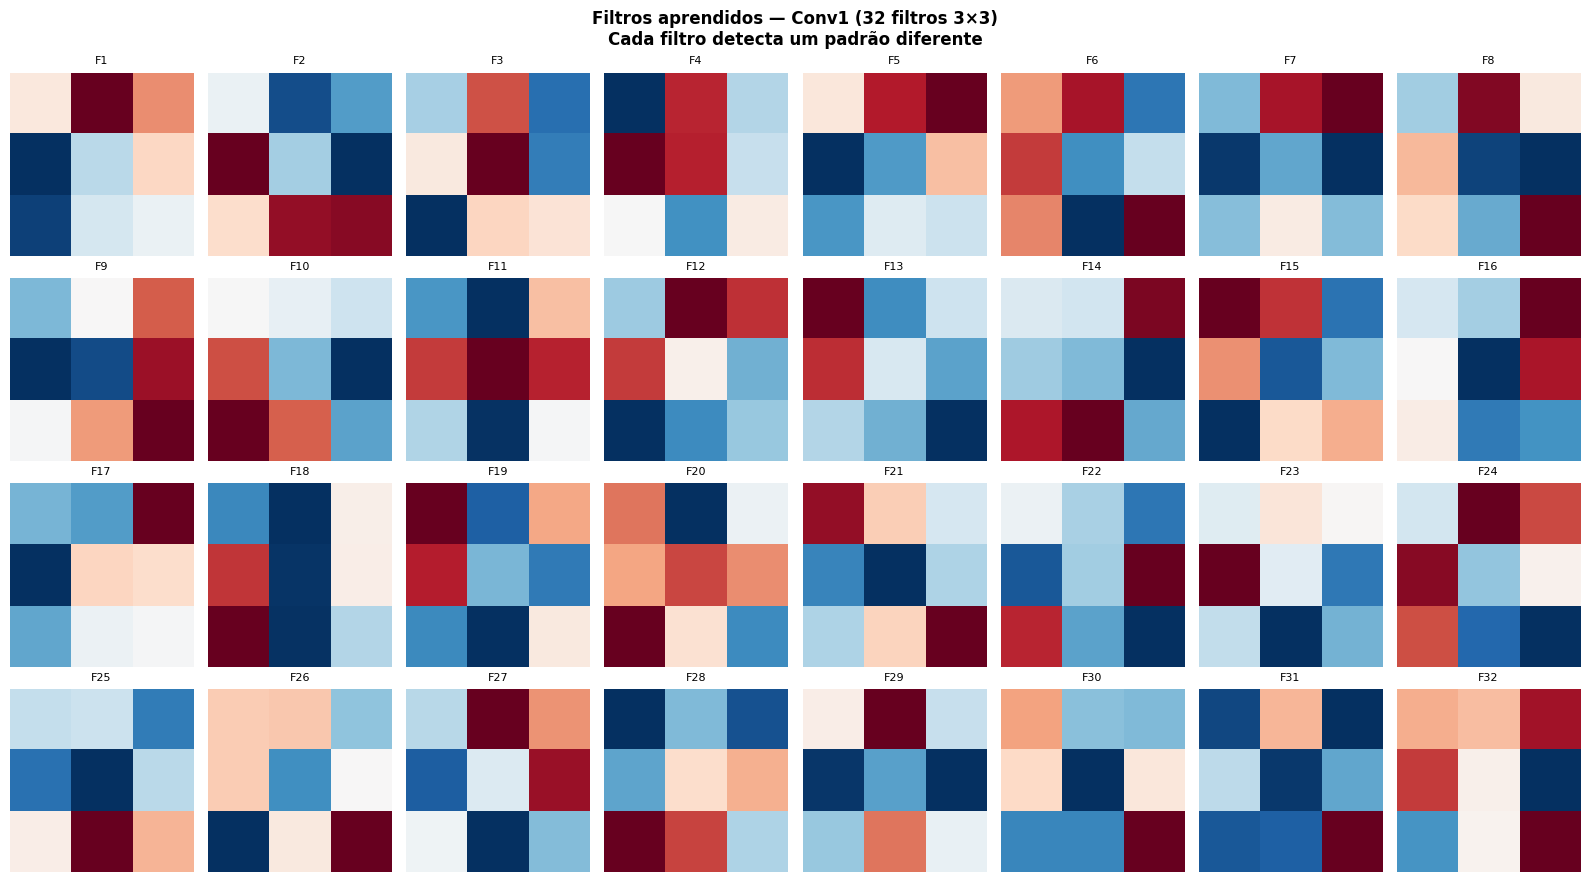

In [45]:
# ── Etapa 8: Visualizando filtros aprendidos ──────────────────
pesos_conv1 = net_mnist.conv1.weight.detach().cpu()
print(f'Pesos conv1: {list(pesos_conv1.shape)}  (32 filtros, 1 canal, 3×3)')

fig, axes = plt.subplots(4, 8, figsize=(16, 9))
for idx, ax in enumerate(axes.flatten()):
    filtro = pesos_conv1[idx, 0].numpy()
    im = ax.imshow(filtro, cmap='RdBu',
                   vmin=filtro.min(), vmax=filtro.max())
    ax.set_title(f'F{idx+1}', fontsize=8)
    ax.axis('off')

plt.suptitle('Filtros aprendidos — Conv1 (32 filtros 3×3)\nCada filtro detecta um padrão diferente',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

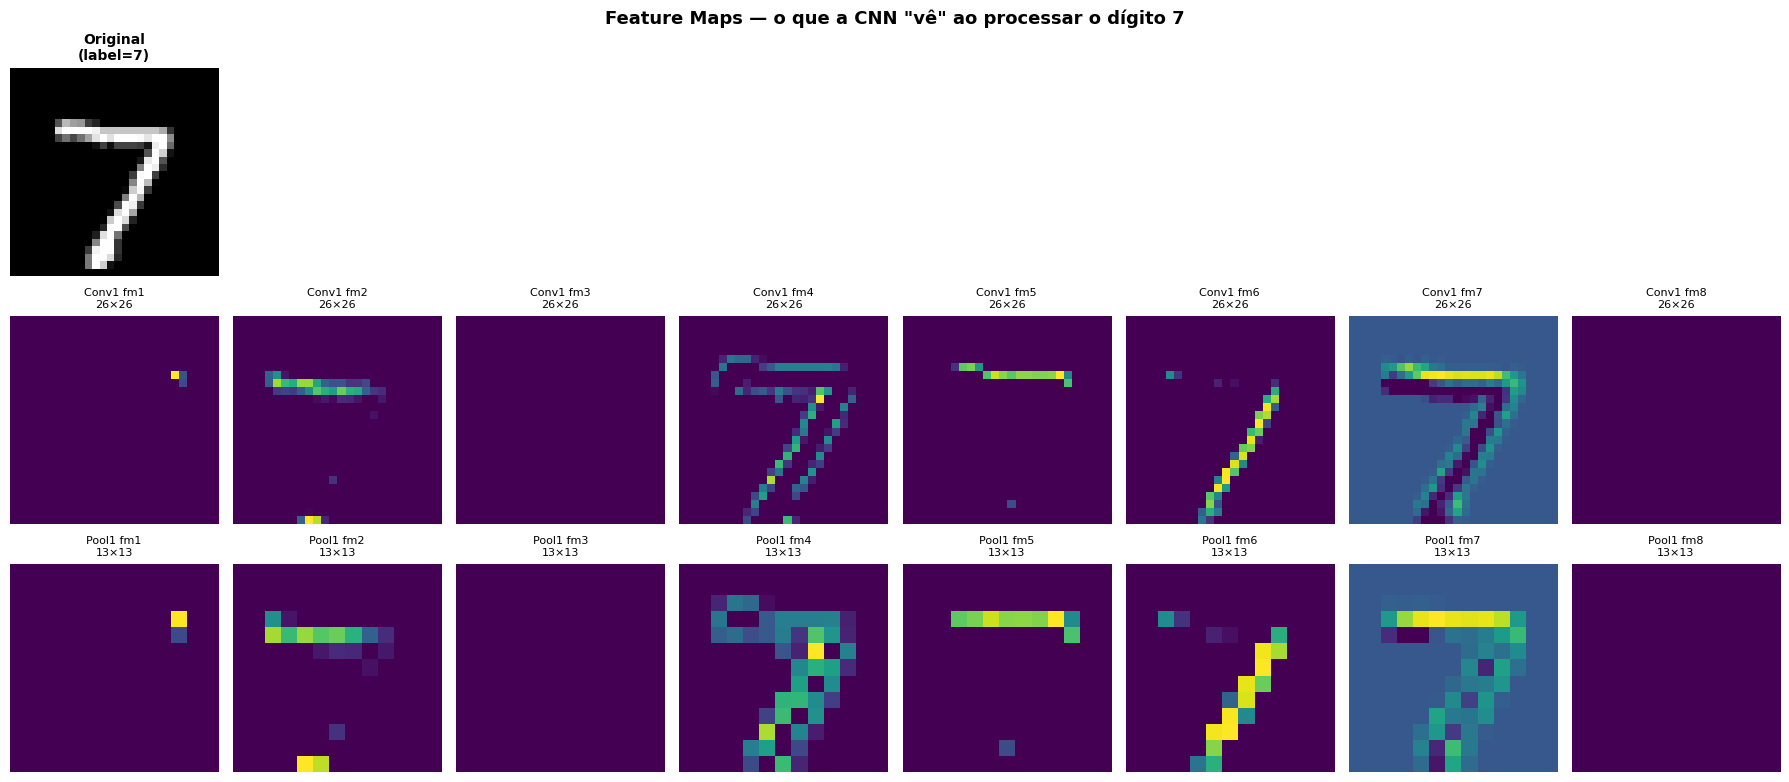

In [46]:
# ── Etapa 9: Feature maps de uma imagem de teste ─────────────
net_mnist.eval()
img_teste, label_teste = mnist_test[0]
img_t = img_teste.unsqueeze(0).to(device_mnist)

with torch.no_grad():
    # Após conv1+BN+ReLU
    fm_depois_conv1 = net_mnist.activation(
        net_mnist.bnorm(net_mnist.conv1(img_t))
    )
    # Após pool
    fm_depois_pool1 = net_mnist.pool(fm_depois_conv1)

fig, axes = plt.subplots(3, 8, figsize=(18, 8))

axes[0, 0].imshow(img_teste.squeeze().numpy(), cmap='gray')
axes[0, 0].set_title(f'Original\n(label={label_teste})', fontsize=10, fontweight='bold')
axes[0, 0].axis('off')
for i in range(1, 8):
    axes[0, i].axis('off')

for i in range(8):
    axes[1, i].imshow(fm_depois_conv1[0, i].cpu().numpy(), cmap='viridis')
    axes[1, i].set_title(f'Conv1 fm{i+1}\n26×26', fontsize=8)
    axes[1, i].axis('off')

for i in range(8):
    axes[2, i].imshow(fm_depois_pool1[0, i].cpu().numpy(), cmap='viridis')
    axes[2, i].set_title(f'Pool1 fm{i+1}\n13×13', fontsize=8)
    axes[2, i].axis('off')

plt.suptitle(f'Feature Maps — o que a CNN "vê" ao processar o dígito {label_teste}',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Resumo Comparativo Final

| Aspecto | MLP (Dense) | CNN |
|---------|------------|-----|
| **Parâmetros** | Muitos (cresce com tamanho da imagem) | Poucos (kernel compartilhado) |
| **Invariância a translação** | ❌ Não | ✅ Sim (feature maps) |
| **Extração de features** | ❌ Não (pixels brutos) | ✅ Sim (hierárquica) |
| **Eficiência computacional** | Baixa | Alta |
| **Adequação a imagens** | Fraca | Excelente |

### Anatomia de uma CNN

```
Entrada (Imagem)
     │
     ▼
┌─────────────────────────────┐
│  BLOCO CONVOLUCIONAL × N   │  ← Extração de Features
│  Conv2d → BN → ReLU → Pool │
└─────────────────────────────┘
     │
     ▼
  Flatten
     │
     ▼
┌─────────────────────────────┐
│  CABEÇA CLASSIFICADORA × M │  ← Classificação
│  Linear → ReLU → Dropout   │
└─────────────────────────────┘
     │
     ▼
  Linear → Softmax/Sigmoid
     │
     ▼
   Predição
```

---
### Referências

- Russell & Norvig, *Artificial Intelligence: A Modern Approach*, Cap. 22 — Deep Learning  
- Warfield, D., *Convolutional Networks — Intuitively and Exhaustively Explained*, TDS Archive  
- Jorgecardete, *Convolutional Neural Networks: A Comprehensive Guide*, The Deep Hub  
- Manogaran, V., *Convolutional Neural Network*, 2020  
- Notebook AC_2 — Rede Convolucional MNIST (IBMEC, 2026)